[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IzadoraGalarza/TP1_G5_IA/blob/parte-3-rede-neural-samuel/notebooks/parte3_rede_neural.ipynb)

# Etapa 3 - Rede Neural

**Responsável: Samuel Ferreira Alves Vieira**

Esta parte compara arquiteturas, regularização `alpha` e `early_stopping` do `MLPClassifier`. O pré-processamento permanece fixo conforme a Etapa 2: limpeza conservadora, `onehot_rare` e `StandardScaler`.

## Protocolo

- Apenas `treino.csv`; o teste não participa de ajuste ou seleção.
- Limpeza `F_E_mais_suspeitas` da Etapa 2.
- Imputação, codificação e normalização ajustadas dentro de cada dobra.
- `StratifiedGroupKFold` com 3 dobras e semente 42.
- Assinaturas idênticas ficam na mesma dobra.
- Métrica principal: F1-macro; também reportamos precisão e recall de cada classe.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

REPOSITORY = 'https://github.com/IzadoraGalarza/TP1_G5_IA.git'
BRANCH = 'parte-3-rede-neural-samuel'

if Path('/content').exists():
    project_root = Path('/content/TP1_G5_IA_rede_neural_samuel')
    if not project_root.exists():
        subprocess.run(['git', 'clone', '--branch', BRANCH, REPOSITORY, str(project_root)], check=True)
    os.chdir(project_root)
else:
    project_root = Path.cwd()
    if project_root.name == 'notebooks':
        project_root = project_root.parent
        os.chdir(project_root)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
print('Projeto carregado.')

Projeto carregado.


In [2]:
import pandas as pd
from IPython.display import Image, display

from src.stage3_neural_network import default_grid, run_grid, split_features_target

raw = pd.read_csv(project_root / 'data' / 'treino.csv')
X, y = split_features_target(raw)
print('Base bruta:', raw.shape)
print('Base limpa:', X.shape)
display(y.map({0: 'normal', 1: 'anomaly'}).value_counts().rename('quantidade').to_frame())

Base bruta: (69833, 50)
Base limpa: (55063, 39)


,quantidade
class,
normal,53246
anomaly,1817


## Grade experimental

A grade possui 18 combinações: arquiteturas `(64,)`, `(64, 32)` e `(128,)`, `alpha` em `{0.0001, 0.001, 0.01}` e early stopping ligado/desligado. Mantemos ReLU, Adam, lote 256, taxa inicial 0,001 e máximo de 180 iterações.

In [3]:
OUTPUT_DIR = project_root / 'output' / 'etapa_3'
REEXECUTAR_GRADE = True

if REEXECUTAR_GRADE:
    results, fold_results = run_grid(
        X, y, default_grid(), n_splits=3, max_iter=180, output_dir=OUTPUT_DIR
    )
else:
    results = pd.read_csv(OUTPUT_DIR / 'resultados_rede_neural.csv')
    fold_results = pd.read_csv(OUTPUT_DIR / 'resultados_rede_neural_por_dobra.csv')

columns = [
    'arquitetura', 'alpha', 'early_stopping', 'f1_macro', 'f1_macro_std',
    'precision_normal', 'recall_normal', 'precision_anomaly', 'recall_anomaly',
    'iteracoes_media', 'tempo_s'
]
display(results[columns].round(4))

[1/18] arquitetura=64, alpha=0.0001, early_stopping=True


    F1-macro=0.9475 ± 0.0076


[2/18] arquitetura=64, alpha=0.0001, early_stopping=False


    F1-macro=0.9638 ± 0.0030


[3/18] arquitetura=64, alpha=0.001, early_stopping=True


    F1-macro=0.9508 ± 0.0093


... (27 outputs left out)

    F1-macro=0.9518 ± 0.0024


[18/18] arquitetura=128, alpha=0.01, early_stopping=False


    F1-macro=0.9646 ± 0.0049


,arquitetura,alpha,early_stopping,f1_macro,f1_macro_std,precision_normal,recall_normal,precision_anomaly,recall_anomaly,iteracoes_media,tempo_s
0,128,0.0001,False,0.9656,0.0052,0.9970,0.9986,0.9571,0.9108,94.0000,17.5160
1,128,0.0010,False,0.9654,0.0059,0.9969,0.9986,0.9581,0.9092,94.0000,17.5427
2,128,0.0100,False,0.9646,0.0049,0.9967,0.9988,0.9613,0.9034,101.3333,18.7225
3,64,0.0001,False,0.9638,0.0030,0.9966,0.9988,0.9622,0.8999,118.3333,15.6873
4,64,0.0010,False,0.9638,0.0033,0.9966,0.9988,0.9633,0.8988,110.0000,14.9570
5,64x32,0.0001,False,0.9633,0.0065,0.9968,0.9984,0.9518,0.9072,91.3333,16.0994
6,64x32,0.0100,False,0.9620,0.0067,0.9970,0.9981,0.9411,0.9122,85.6667,15.2884
7,64,0.0100,False,0.9610,0.0066,0.9966,0.9984,0.9501,0.9003,81.3333,12.0021
8,64x32,0.0010,False,0.9602,0.0051,0.9968,0.9981,0.9412,0.9055,89.0000,15.6420
9,64x32,0.0010,True,0.9587,0.0065,0.9959,0.9990,0.9667,0.8778,36.0000,8.3978


## Resultado selecionado

A seleção considera primeiro o F1-macro médio e depois o recall de `anomaly`. Diferenças menores que a variação entre dobras não devem ser interpretadas como superioridade estatística.

,melhor_configuracao
arquitetura,128
alpha,0.0001
early_stopping,False
f1_macro,0.965591
f1_macro_std,0.005153
precision_normal,0.996962
recall_normal,0.99861
precision_anomaly,0.957132
recall_anomaly,0.910847
iteracoes_media,94.0


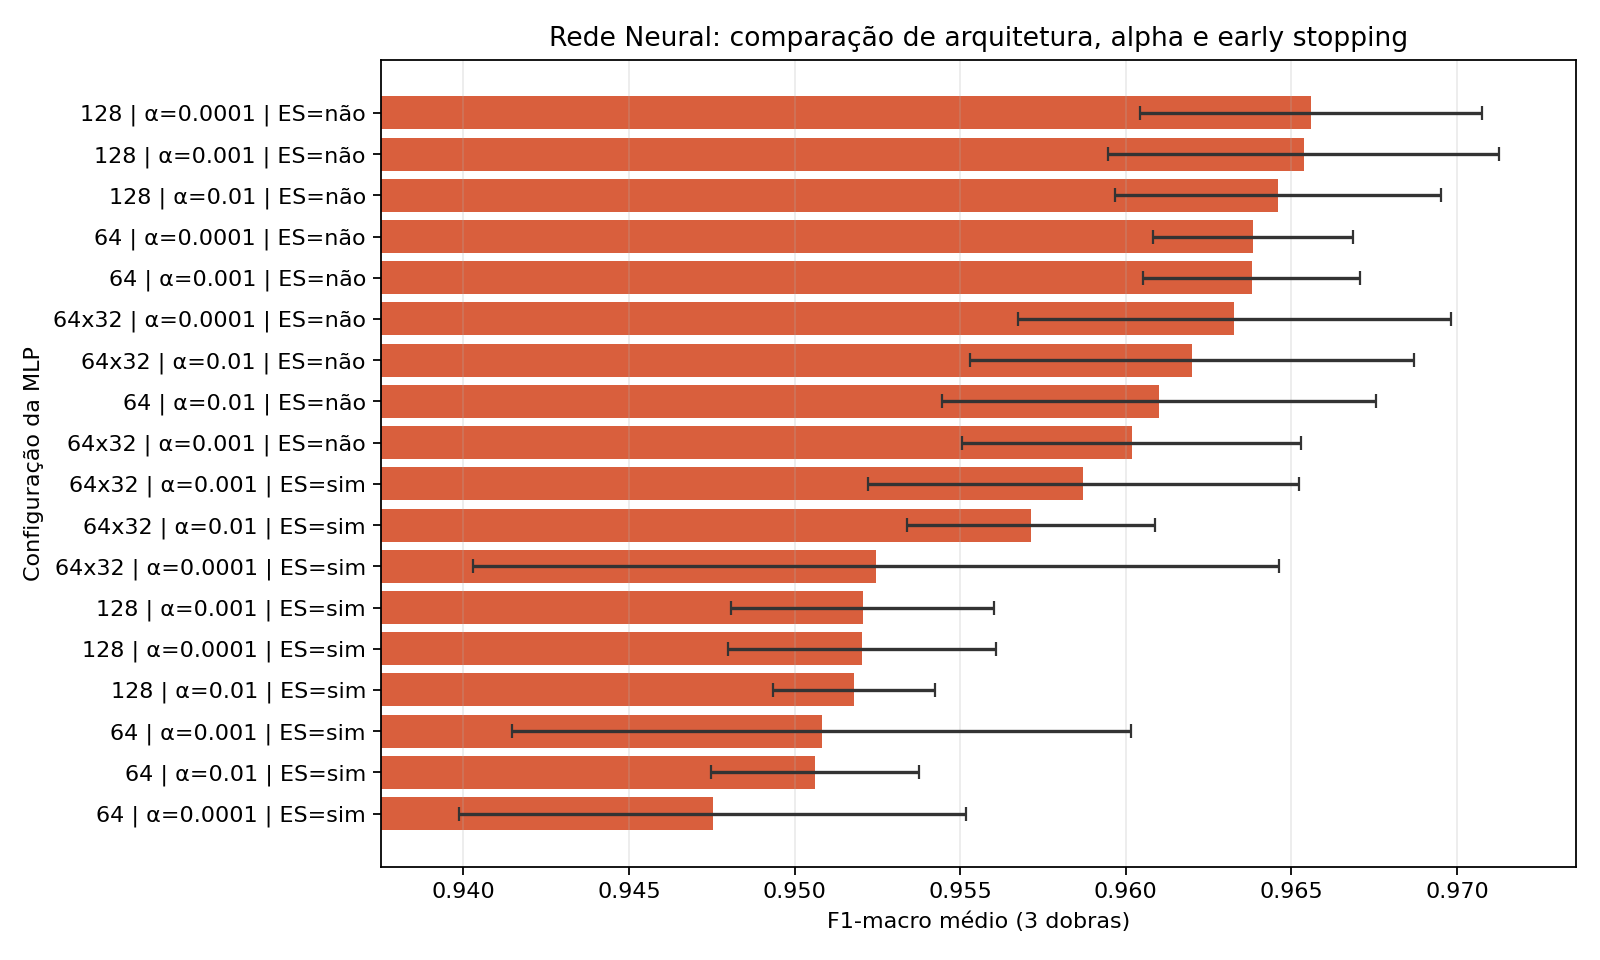

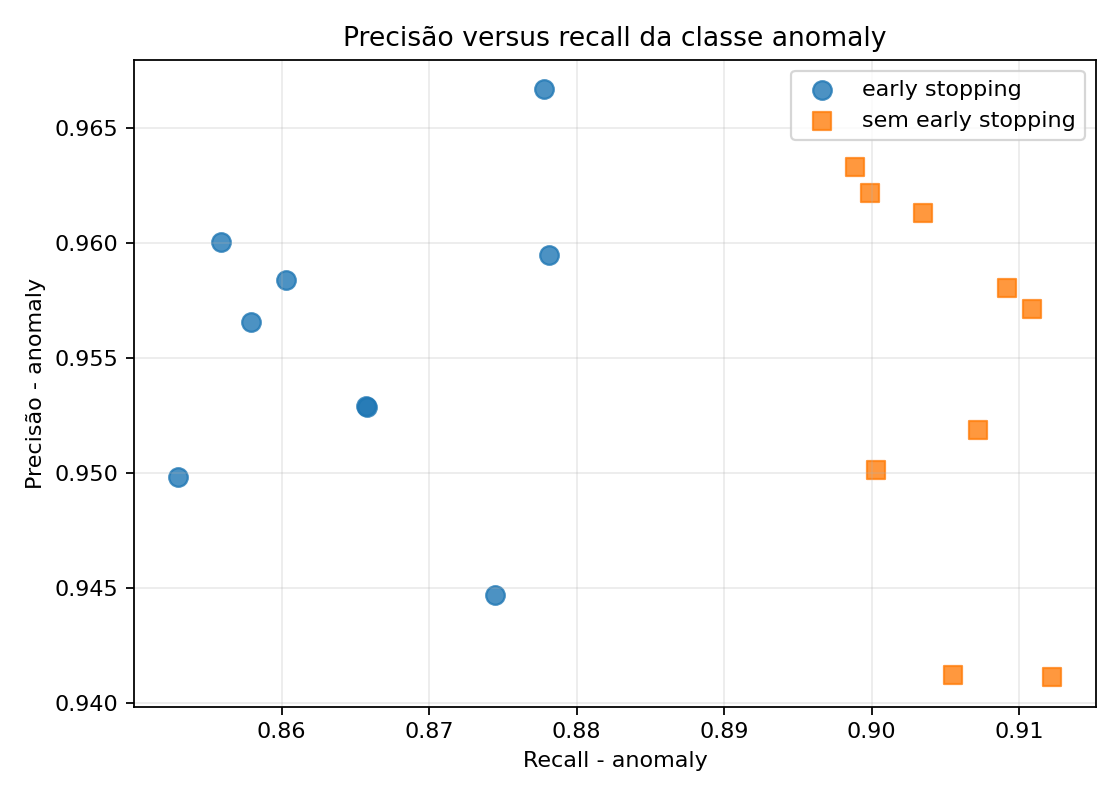

In [4]:
best = results.iloc[0]
display(best[columns].rename('melhor_configuracao').to_frame())
display(Image(filename=str(OUTPUT_DIR / 'rede_neural_f1_macro.png')))
display(Image(filename=str(OUTPUT_DIR / 'rede_neural_precisao_recall_anomaly.png')))

## Discussão

A melhor média observada foi da arquitetura `(128,)`, com `alpha=0.0001` e sem early stopping: F1-macro 0,9656 ± 0,0052. As precisões de `normal` e `anomaly` foram 0,9970 e 0,9571; os recalls foram 0,9986 e 0,9108.

Sem early stopping, as redes obtiveram os maiores F1-macro. Ligá-lo reduziu o número de iterações, mas diminuiu sobretudo o recall de anomalias. A arquitetura com duas camadas não melhorou consistentemente o resultado. A rede com 128 neurônios trouxe um ganho modesto de F1-macro e recall de anomalia. Como os dois melhores valores de `alpha` ficaram próximos em relação ao desvio das dobras, escolhemos 0,0001 pela maior média observada, sem afirmar superioridade estatística.

## Dados para a tabela da pessoa 5

A célula seguinte exporta todas as combinações com F1-macro e precisão/recall por classe.

In [5]:
team_columns = [
    'arquitetura', 'alpha', 'early_stopping', 'f1_macro', 'f1_macro_std',
    'precision_normal', 'recall_normal', 'precision_anomaly', 'recall_anomaly'
]
team_table = results[team_columns].copy()
team_path = OUTPUT_DIR / 'resultados_rede_neural_para_tabela.csv'
team_table.to_csv(team_path, index=False)
display(team_table.round(4))
print('Arquivo para consolidação:', team_path)

,arquitetura,alpha,early_stopping,f1_macro,f1_macro_std,precision_normal,recall_normal,precision_anomaly,recall_anomaly
0,128,0.0001,False,0.9656,0.0052,0.9970,0.9986,0.9571,0.9108
1,128,0.0010,False,0.9654,0.0059,0.9969,0.9986,0.9581,0.9092
2,128,0.0100,False,0.9646,0.0049,0.9967,0.9988,0.9613,0.9034
3,64,0.0001,False,0.9638,0.0030,0.9966,0.9988,0.9622,0.8999
4,64,0.0010,False,0.9638,0.0033,0.9966,0.9988,0.9633,0.8988
5,64x32,0.0001,False,0.9633,0.0065,0.9968,0.9984,0.9518,0.9072
6,64x32,0.0100,False,0.9620,0.0067,0.9970,0.9981,0.9411,0.9122
7,64,0.0100,False,0.9610,0.0066,0.9966,0.9984,0.9501,0.9003
8,64x32,0.0010,False,0.9602,0.0051,0.9968,0.9981,0.9412,0.9055
9,64x32,0.0010,True,0.9587,0.0065,0.9959,0.9990,0.9667,0.8778


Arquivo para consolidação: /private/tmp/tpia-stage3.3cADtK/worktree/output/etapa_3/resultados_rede_neural_para_tabela.csv
